# Financial Econometrics — Group Work Project 1: Code Notebook

This notebook holds all of the code behind the written report. The report
itself contains the answers, derivations, tables and figures; this notebook
produces every number and figure used there.

**Data files.** Place the two course files in the `data/` folder next to
this notebook before running:

* `data/FE-GWP1_model_selection_1.csv` (Problem 3a)
* `data/FE-GWP1_dataset_Prob5.csv` (Problem 5c)

Run with *Kernel → Restart & Run All*. Every random step uses a fixed seed,
so the output is reproducible.

In [1]:
import os, json, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen, VECM, select_order
from statsmodels.tsa.arima_process import arma2ma, arma_acf, ArmaProcess
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

DATA_DIR = os.environ.get("GWP_DATA_DIR", "data")
OUT = os.environ.get("GWP_OUT_DIR", "outputs")
FIG, TAB = os.path.join(OUT, "figures"), os.path.join(OUT, "tables")
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
RESULTS = {}  # key numbers used in the report

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight")
    plt.show()

def savetab(df, name, floatfmt=".4f", index=True):
    """Save a table as pipe-markdown so the report can include it."""
    df.to_csv(os.path.join(TAB, name + ".csv"), index=index)
    shown = df.copy()
    for c in shown.columns:  # print whole numbers without decimals
        col = shown[c]
        if pd.api.types.is_numeric_dtype(col) and col.dropna().size and np.allclose(col.dropna() % 1, 0) \
                and col.dropna().abs().max() >= 1 and c not in ("rho",):
            shown[c] = col.map(lambda v: "–" if pd.isna(v) else f"{int(round(v)):,}")
    with open(os.path.join(TAB, name + ".md"), "w") as f:
        f.write(shown.to_markdown(floatfmt=floatfmt, index=index))
    return df

def ols(y, X):
    """Plain OLS with an intercept, via statsmodels."""
    return sm.OLS(y, sm.add_constant(X)).fit()

---
## Problem 1 — Omitted variable bias

Questions 1a to 1d are analytical and are answered in the report.
Below is a small numerical check of the 1b/1c formulas, followed by the
simulation study for 1e.

### Check of 1b and 1c
We build x and w to be exactly orthogonal in the sample (after centring),
generate y from the full model (1), estimate the short model (2), and
compare the estimated γ with the closed-form expression from 1c.

In [2]:
rng = np.random.default_rng(101)
n = 400
x = rng.normal(size=n); x -= x.mean()
w = rng.normal(size=n); w -= w.mean()
w -= (w @ x) / (x @ x) * x              # make w exactly orthogonal to x
z = 0.8 * w - 0.4 * x + rng.normal(size=n)
alpha, beta, gamma, delta = 1.0, 2.0, -1.0, 1.5
y = alpha + beta * x + gamma * w + delta * z + rng.normal(size=n)

short = ols(y, np.column_stack([x, w]))
b_simple = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
g_simple = np.sum((w - w.mean()) * (y - y.mean())) / np.sum((w - w.mean()) ** 2)
d_wz = np.sum((w - w.mean()) * (z - z.mean())) / np.sum((w - w.mean()) ** 2)
long_ = ols(y, np.column_stack([x, w, z]))
check1 = pd.DataFrame({
    "short-model OLS": short.params[1:3],
    "simple-regression formula (1b)": [b_simple, g_simple],
    "long-model OLS": long_.params[1:3],
}, index=["beta", "gamma"])
print(check1)
print("\nPredicted gamma-hat from 1c: gamma_hat_long + delta_hat * d_wz =",
      round(long_.params[2] + long_.params[3] * d_wz, 6))

       short-model OLS  simple-regression formula (1b)  long-model OLS
beta            1.4461                          1.4461          1.9492
gamma          -0.0484                         -0.0484         -1.0501

Predicted gamma-hat from 1c: gamma_hat_long + delta_hat * d_wz = -0.048357


### 1e — Simulation of omitted variable bias

**Design.** True model $Y_i = a + bX_i + cZ_i + e_i$ with
$a = 1$, $b = 2$, $c = 3$.

* $X_i \sim N(0,1)$
* $Z_i = \rho X_i + u_i$, $u_i \sim N(0,1)$, so X and Z are correlated when $\rho \neq 0$.
* $e_i \sim N(0,1)$, drawn independently of both X and Z.

We fit the long regression (X and Z) and the short regression (X only).
Theory says the short-regression slope converges to
$b + c\,\mathrm{Cov}(X,Z)/\mathrm{Var}(X) = b + c\rho$.
With $\rho = 0.6$ that is $2 + 3(0.6) = 3.8$.

In [3]:
a_true, b_true, c_true = 1.0, 2.0, 3.0

def simulate_once(n, rho, rng):
    X = rng.normal(size=n)
    Z = rho * X + rng.normal(size=n)
    e = rng.normal(size=n)
    Y = a_true + b_true * X + c_true * Z + e
    one = np.ones(n)
    b_long = np.linalg.lstsq(np.column_stack([one, X, Z]), Y, rcond=None)[0][1]
    b_short = np.linalg.lstsq(np.column_stack([one, X]), Y, rcond=None)[0][1]
    return b_long, b_short, np.corrcoef(X, Z)[0, 1]

# One sample of n = 200, printed in full
rng = np.random.default_rng(2024)
n = 200
X = rng.normal(size=n); Z = 0.6 * X + rng.normal(size=n); e = rng.normal(size=n)
Y = a_true + b_true * X + c_true * Z + e
m_long = ols(Y, pd.DataFrame({"X": X, "Z": Z}))
m_short = ols(Y, pd.DataFrame({"X": X}))
print(m_long.summary().tables[1]); print(m_short.summary().tables[1])
one_run = pd.DataFrame({
    "Estimate": [m_long.params["X"], m_short.params["X"]],
    "Std. error": [m_long.bse["X"], m_short.bse["X"]],
    "95% CI low": [m_long.conf_int().loc["X", 0], m_short.conf_int().loc["X", 0]],
    "95% CI high": [m_long.conf_int().loc["X", 1], m_short.conf_int().loc["X", 1]],
    "R-squared": [m_long.rsquared, m_short.rsquared],
}, index=["Long model (X, Z)", "Short model (X only)"])
savetab(one_run, "p1e_one_run")
RESULTS["p1e_corrXZ"] = float(np.corrcoef(X, Z)[0, 1])
one_run

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0449      0.072     14.559      0.000       0.903       1.186
X              2.0099      0.081     24.695      0.000       1.849       2.170
Z              2.9511      0.071     41.317      0.000       2.810       3.092
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9900      0.223      4.449      0.000       0.551       1.429
X              3.5349      0.225     15.715      0.000       3.091       3.979


,Estimate,Std. error,95% CI low,95% CI high,R-squared
"Long model (X, Z)",2.0099,0.0814,1.8494,2.1704,0.9540
Short model (X only),3.5349,0.2249,3.0914,3.9785,0.5550


**Monte Carlo over sample sizes.** For each sample size we repeat the
experiment many times and record the mean and standard deviation of
$\hat b$ from both regressions. We run it for correlated regressors
($\rho = 0.6$) and, as a control, for independent regressors ($\rho = 0$).

In [4]:
rng = np.random.default_rng(7)
sizes = [30, 100, 1_000, 10_000, 100_000]
reps = {30: 2000, 100: 2000, 1_000: 2000, 10_000: 1000, 100_000: 200}
rows, draws = [], {}
for rho in [0.6, 0.0]:
    for n in sizes:
        sims = np.array([simulate_once(n, rho, rng) for _ in range(reps[n])])
        draws[(rho, n)] = sims
        rows.append({"rho": rho, "n": n, "replications": reps[n],
                     "mean b_hat (long)": sims[:, 0].mean(),
                     "sd b_hat (long)": sims[:, 0].std(ddof=1),
                     "mean b_hat (short)": sims[:, 1].mean(),
                     "sd b_hat (short)": sims[:, 1].std(ddof=1),
                     "theory plim (short)": b_true + c_true * rho})
mc = pd.DataFrame(rows)
savetab(mc, "p1e_montecarlo", index=False)
mc

,rho,n,replications,mean b_hat (long),sd b_hat (long),mean b_hat (short),sd b_hat (short),theory plim (short)
0,0.6000,30,2000,2.0019,0.2242,3.7855,0.6065,3.8000
1,0.6000,100,2000,2.0011,0.1207,3.8079,0.3053,3.8000
2,0.6000,1000,2000,2.0004,0.0369,3.8016,0.0987,3.8000
3,0.6000,10000,1000,2.0001,0.0116,3.8015,0.0324,3.8000
4,0.6000,100000,200,2.0001,0.0036,3.7992,0.0095,3.8000
5,0.0000,30,2000,1.9920,0.1962,1.9982,0.5916,2.0000
6,0.0000,100,2000,2.0034,0.1013,2.0094,0.3230,2.0000
7,0.0000,1000,2000,1.9989,0.0315,1.9981,0.0982,2.0000
8,0.0000,10000,1000,2.0000,0.0100,2.0011,0.0316,2.0000
9,0.0000,100000,200,2.0001,0.0032,2.0007,0.0103,2.0000


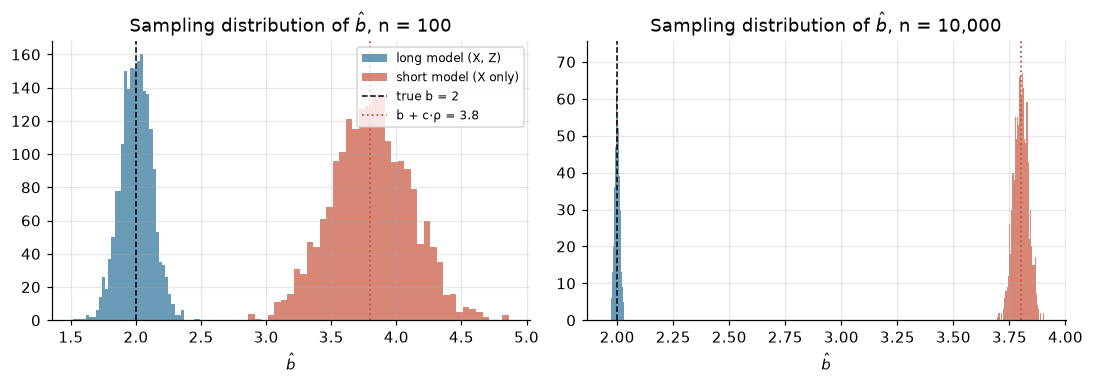

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, n in zip(axes, [100, 10_000]):
    s = draws[(0.6, n)]
    ax.hist(s[:, 0], bins=40, alpha=0.7, label=r"long model (X, Z)", color="#2a6f97")
    ax.hist(s[:, 1], bins=40, alpha=0.7, label=r"short model (X only)", color="#c8553d")
    ax.axvline(b_true, color="k", ls="--", lw=1, label="true b = 2")
    ax.axvline(b_true + c_true * 0.6, color="#c8553d", ls=":", lw=1.2, label="b + c·ρ = 3.8")
    ax.set_title(f"Sampling distribution of $\\hat b$, n = {n:,}")
    ax.set_xlabel(r"$\hat b$")
axes[0].legend(fontsize=8)
savefig("p1e_hist")

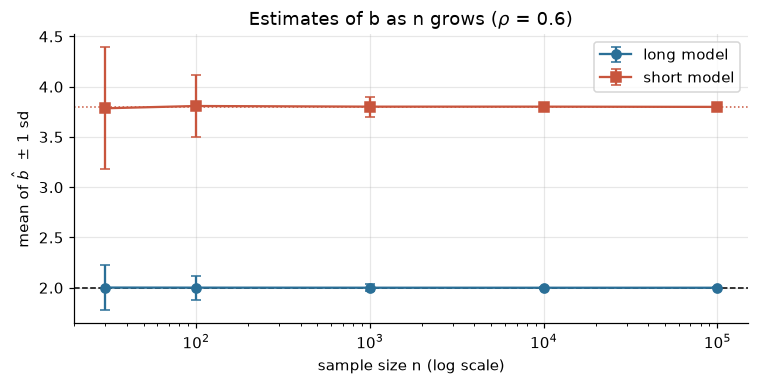

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sub = mc[mc.rho == 0.6]
ax.errorbar(sub.n, sub["mean b_hat (long)"], yerr=sub["sd b_hat (long)"], fmt="o-",
            capsize=3, label="long model", color="#2a6f97")
ax.errorbar(sub.n, sub["mean b_hat (short)"], yerr=sub["sd b_hat (short)"], fmt="s-",
            capsize=3, label="short model", color="#c8553d")
ax.axhline(2, color="k", ls="--", lw=1); ax.axhline(3.8, color="#c8553d", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("sample size n (log scale)")
ax.set_ylabel(r"mean of $\hat b$  ± 1 sd")
ax.set_title(r"Estimates of b as n grows ($\rho$ = 0.6)")
ax.legend()
savefig("p1e_by_n")

---
## Problem 2 — Outliers

### 2b — Simulation

**Design.**
1. Baseline ("clean") data: $n = 50$, $x_i \sim U(0,10)$,
   $y_i = 2 + 1.5x_i + \varepsilon_i$, $\varepsilon_i \sim N(0,1)$, seed 11.
2. We then create four contaminated copies of the same 50 points:
   * **B. Vertical outlier:** add one point at the centre of the x-range, $(5,\; 2+1.5\cdot5+25)$.
   * **C. Bad leverage point:** add one point far to the right, $(25,\; 2)$, well below the true line (which gives 39.5 at x = 25).
   * **D. Good leverage point:** add one point at $x = 25$ that lies on the true line (plus normal noise).
   * **E. Cluster of outliers:** shift the y-values of 5 randomly chosen points (10% of the sample) up by 15.
3. Each data set is fitted by OLS. We record the intercept, slope, slope standard
   error, residual standard error and $R^2$, and the leverage and Cook's distance of
   the added point. As a reference we also fit a Huber M-estimator (robust regression).
4. Finally we move a single added point's y-value across a grid, at a central x and at
   an extreme x, to show how the slope responds.

In [7]:
rng = np.random.default_rng(11)
n0 = 50
x0 = rng.uniform(0, 10, n0)
y0 = 2 + 1.5 * x0 + rng.normal(0, 1, n0)

scen = {"A. Clean data": (x0, y0, None)}
scen["B. Vertical outlier (x=5)"] = (np.append(x0, 5.0), np.append(y0, 2 + 1.5 * 5 + 25), n0)
scen["C. Bad leverage point (x=25, y=2)"] = (np.append(x0, 25.0), np.append(y0, 2.0), n0)
scen["D. Good leverage point (x=25, on line)"] = (np.append(x0, 25.0), np.append(y0, 2 + 1.5 * 25 + rng.normal()), n0)
idx = rng.choice(n0, 5, replace=False)
yE = y0.copy(); yE[idx] += 15
scen["E. 10% of points shifted up by 15"] = (x0, yE, idx)

rows = []
fits = {}
for name, (xs, ys, k) in scen.items():
    f = ols(ys, xs)
    fits[name] = f
    infl = f.get_influence()
    rlm = sm.RLM(ys, sm.add_constant(xs), M=sm.robust.norms.HuberT()).fit()
    lev = cook = np.nan
    if isinstance(k, (int, np.integer)):
        lev = infl.hat_matrix_diag[k]; cook = infl.cooks_distance[0][k]
    rows.append({"Scenario": name, "n": len(xs), "alpha_hat": f.params[0], "beta_hat": f.params[1],
                 "SE(beta_hat)": f.bse[1], "resid. SE": np.sqrt(f.scale), "R2": f.rsquared,
                 "leverage h (added pt)": lev, "Cook's D (added pt)": cook,
                 "Huber beta_hat": rlm.params[1]})
p2b = pd.DataFrame(rows).set_index("Scenario")
savetab(p2b, "p2b_scenarios", floatfmt=".3f")
p2b

,n,alpha_hat,beta_hat,SE(beta_hat),resid. SE,R2,leverage h (added pt),Cook's D (added pt),Huber beta_hat
Scenario,,,,,,,,,
A. Clean data,50,2.1925,1.4958,0.0465,0.9744,0.9557,NaN,NaN,1.4924
B. Vertical outlier (x=5),51,2.5800,1.5173,0.1737,3.6414,0.6090,0.0199,0.4635,1.4929
"C. Bad leverage point (x=25, y=2)",51,5.9013,0.6086,0.1357,3.9490,0.2911,0.4914,22.2578,1.4125
"D. Good leverage point (x=25, on line)",51,2.2735,1.4764,0.0333,0.9680,0.9757,0.4914,0.1768,1.4696
E. 10% of points shifted up by 15,50,3.0287,1.6397,0.2110,4.4238,0.5570,NaN,NaN,1.5211


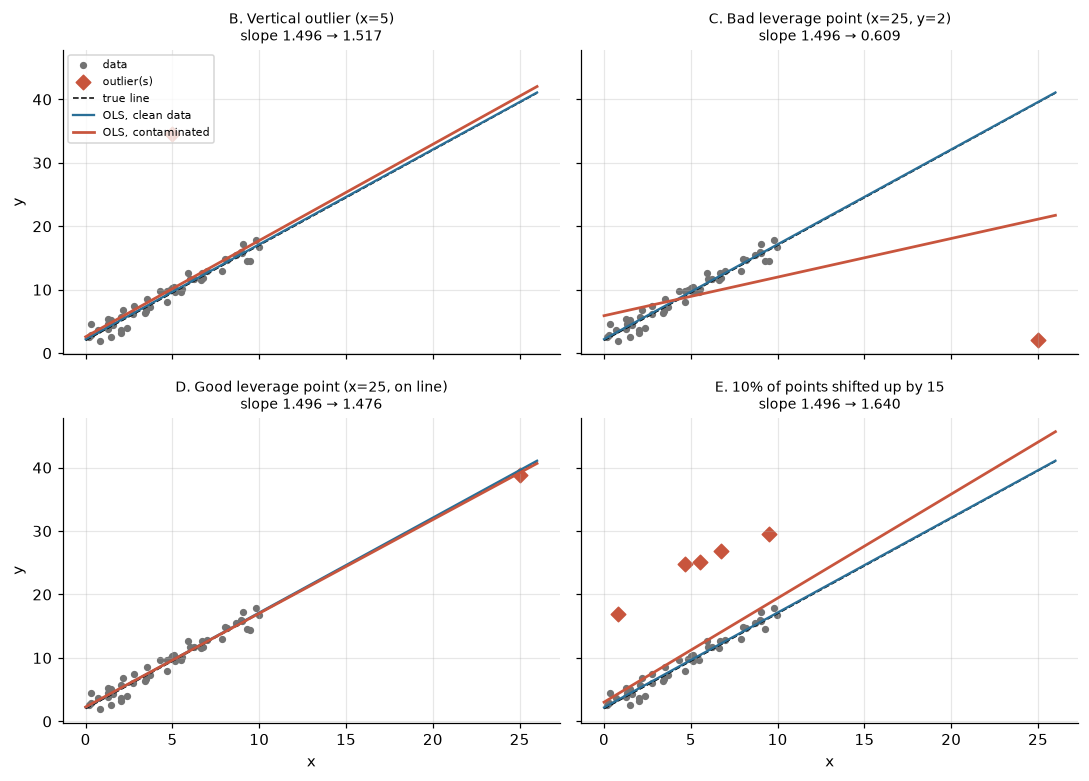

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), sharex=True, sharey=True)
grid = np.linspace(0, 26, 100)
fA = fits["A. Clean data"]
for ax, name in zip(axes.ravel(), list(scen)[1:]):
    xs, ys, k = scen[name]
    f = fits[name]
    mask = np.zeros(len(xs), bool)
    if isinstance(k, (int, np.integer)): mask[k] = True
    else: mask[k] = True
    ax.scatter(xs[~mask], ys[~mask], s=14, color="0.45", label="data")
    ax.scatter(xs[mask], ys[mask], s=45, color="#c8553d", marker="D", label="outlier(s)")
    ax.plot(grid, 2 + 1.5 * grid, "k--", lw=1, label="true line")
    ax.plot(grid, fA.params[0] + fA.params[1] * grid, color="#2a6f97", lw=1.5, label="OLS, clean data")
    ax.plot(grid, f.params[0] + f.params[1] * grid, color="#c8553d", lw=1.8, label="OLS, contaminated")
    ax.set_title(f"{name}\nslope {fA.params[1]:.3f} → {f.params[1]:.3f}", fontsize=9)
axes[0, 0].legend(fontsize=7, loc="upper left")
for ax in axes[1]: ax.set_xlabel("x")
for ax in axes[:, 0]: ax.set_ylabel("y")
savefig("p2b_scenarios")

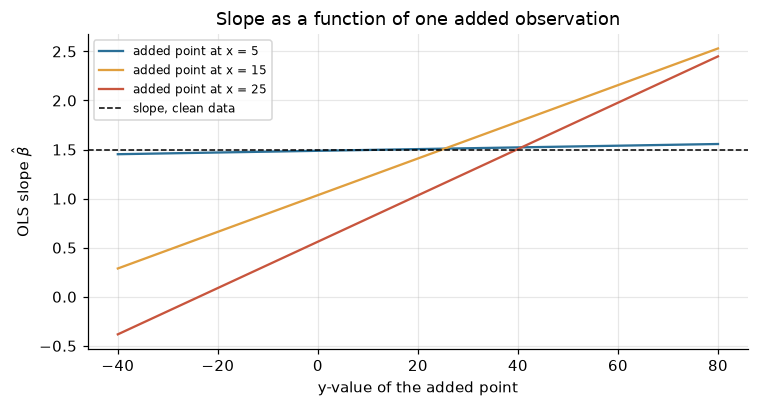

In [9]:
# Sensitivity curve: add one point (x*, y*), move y* over a grid, record the slope
ygrid = np.linspace(-40, 80, 121)
fig, ax = plt.subplots(figsize=(7, 3.8))
sens = {}
for xstar, col in [(5.0, "#2a6f97"), (15.0, "#e09f3e"), (25.0, "#c8553d")]:
    slopes = [ols(np.append(y0, ys_), np.append(x0, xstar)).params[1] for ys_ in ygrid]
    sens[xstar] = slopes
    ax.plot(ygrid, slopes, color=col, label=f"added point at x = {xstar:g}")
ax.axhline(fA.params[1], color="k", ls="--", lw=1, label="slope, clean data")
ax.set_xlabel("y-value of the added point"); ax.set_ylabel(r"OLS slope $\hat\beta$")
ax.set_title("Slope as a function of one added observation")
ax.legend(fontsize=8)
savefig("p2b_sensitivity")
RESULTS["p2b_sens_range_x5"] = [float(min(sens[5.0])), float(max(sens[5.0]))]
RESULTS["p2b_sens_range_x25"] = [float(min(sens[25.0])), float(max(sens[25.0]))]

### 2c — Numerical check of the limit result
$n-1 = 20$ points lie on $y = 0$ at $x = 0, 0.5, \dots, 9.5$. A single point
$(x_n, y_n)$ is added. We use two cases: $y_n = 0.5\,x_n$ (so $y_n/x_n = 0.5$),
and a fixed $y_n = 10$ (so $y_n/x_n \to 0$).

In [10]:
xb = np.arange(0, 10, 0.5); yb = np.zeros_like(xb)
rows = []
for xn in [10, 20, 50, 100, 1_000, 10_000, 100_000]:
    for label, yn in [("y_n = 0.5 x_n", 0.5 * xn), ("y_n = 10", 10.0)]:
        f = ols(np.append(yb, yn), np.append(xb, xn))
        h = f.get_influence().hat_matrix_diag[-1]
        rows.append({"case": label, "x_n": xn, "y_n": yn, "y_n/x_n": yn / xn,
                     "OLS slope": f.params[1], "slope / (y_n/x_n)": f.params[1] / (yn / xn),
                     "leverage h_nn": h})
p2c = pd.DataFrame(rows)
savetab(p2c, "p2c_check", floatfmt=".5g", index=False)
p2c

,case,x_n,y_n,y_n/x_n,OLS slope,slope / (y_n/x_n),leverage h_nn
0,y_n = 0.5 x_n,10,5.0000,0.5000,0.1299,0.2597,0.1775
1,y_n = 10,10,10.0000,1.0000,0.2597,0.2597,0.1775
2,y_n = 0.5 x_n,20,10.0000,0.5000,0.3746,0.7492,0.5916
3,y_n = 10,20,10.0000,0.5000,0.3746,0.7492,0.5916
4,y_n = 0.5 x_n,50,25.0000,0.5000,0.5091,1.0182,0.9252
5,y_n = 10,50,10.0000,0.2000,0.2036,1.0182,0.9252
6,y_n = 0.5 x_n,100,50.0000,0.5000,0.5150,1.0300,0.9820
7,y_n = 10,100,10.0000,0.1000,0.1030,1.0300,0.9820
8,y_n = 0.5 x_n,1000,500.0000,0.5000,0.5023,1.0046,0.9998
9,y_n = 10,1000,10.0000,0.0100,0.0100,1.0046,0.9998


---
## Problem 3 — Model selection
### 3a — Data set `FE-GWP1_model_selection_1.csv`

In [11]:
ms_path = os.path.join(DATA_DIR, "FE-GWP1_model_selection_1.csv")
ms = pd.read_csv(ms_path, encoding="utf-8-sig")
ms.columns = [c.strip() for c in ms.columns]
ms = ms.rename(columns={c: c.lower() for c in ms.columns})
ms = ms[[c for c in ms.columns if c in ["y", "x1", "x2", "x3", "x4", "x5"]]].dropna()
PRED = ["x1", "x2", "x3", "x4", "x5"]
print(ms.shape)
desc = ms.describe().T
savetab(desc, "p3_describe", floatfmt=".3f")
RESULTS["p3_n"] = int(len(ms))
desc

(100, 6)


,count,mean,std,min,25%,50%,75%,max
y,100.0000,1.2574,1.4367,-2.9596,0.3495,1.2785,2.1530,5.1768
x1,100.0000,0.0268,0.4817,-1.2752,-0.3166,0.0402,0.3739,1.0831
x2,100.0000,0.0846,0.9621,-2.0420,-0.6770,0.0404,0.7482,2.9551
x3,100.0000,-0.0160,0.9766,-2.2285,-0.5729,0.0569,0.6364,1.8168
x4,100.0000,0.1224,1.0769,-2.6973,-0.4310,0.2796,0.7479,3.1673
x5,100.0000,-0.2017,1.0734,-3.5264,-0.9602,-0.1858,0.5066,2.4998


In [12]:
corr = ms.corr()
savetab(corr, "p3_corr", floatfmt=".3f")
Xv = sm.add_constant(ms[PRED])
vif = pd.DataFrame({"VIF": [variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])]},
                   index=PRED)
savetab(vif, "p3_vif", floatfmt=".2f")
display(corr); display(vif)

,y,x1,x2,x3,x4,x5
y,1.0000,-0.0614,-0.4193,0.4114,0.5383,-0.2798
x1,-0.0614,1.0000,0.1031,0.0629,-0.0502,0.0612
x2,-0.4193,0.1031,1.0000,-0.0656,-0.0050,-0.0052
x3,0.4114,0.0629,-0.0656,1.0000,-0.0389,-0.1786
x4,0.5383,-0.0502,-0.0050,-0.0389,1.0000,-0.1259
x5,-0.2798,0.0612,-0.0052,-0.1786,-0.1259,1.0000


,VIF
x1,1.0231
x2,1.0168
x3,1.0486
x4,1.0217
x5,1.0578


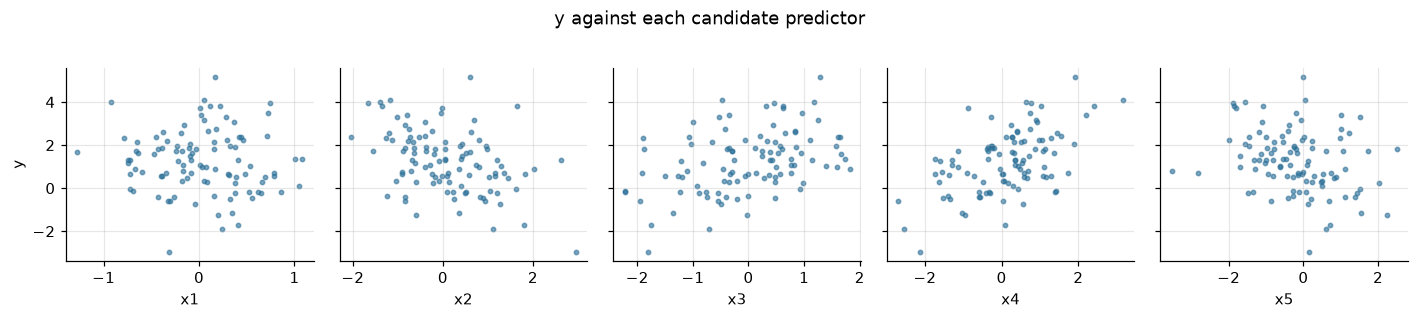

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), sharey=True)
for ax, v in zip(axes, PRED):
    ax.scatter(ms[v], ms["y"], s=8, alpha=0.6, color="#2a6f97")
    ax.set_xlabel(v)
axes[0].set_ylabel("y")
fig.suptitle("y against each candidate predictor", y=1.02)
savefig("p3_scatter")

**Full model.** Start with all five predictors to see the individual t-tests.

In [14]:
full = smf.ols("y ~ " + " + ".join(PRED), data=ms).fit()
print(full.summary())
full_tab = pd.DataFrame({"coef": full.params, "std err": full.bse, "t": full.tvalues, "p-value": full.pvalues})
savetab(full_tab, "p3_full", floatfmt=".4f")
RESULTS["p3_full_r2"] = full.rsquared; RESULTS["p3_full_adjr2"] = full.rsquared_adj

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     34.74
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           5.83e-20
Time:                        17:46:56   Log-Likelihood:                -125.30
No. Observations:                 100   AIC:                             262.6
Df Residuals:                      94   BIC:                             278.2
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1902      0.090     13.246      0.0

**Approach 1 — all-subsets search with adjusted R², AIC and BIC.**
With five predictors there are only $2^5 - 1 = 31$ non-empty models (plus the
intercept-only model), so we can fit every one of them and rank them on each
criterion. For a linear model with Gaussian errors and $k$ estimated mean
parameters (intercept included), statsmodels reports
$\mathrm{AIC} = -2\ln L + 2k$ and $\mathrm{BIC} = -2\ln L + k\ln n$.

In [15]:
def fit_formula(vars_):
    rhs = " + ".join(vars_) if vars_ else "1"
    return smf.ols(f"y ~ {rhs}", data=ms).fit()

rows = []
for k in range(0, 6):
    for comb in itertools.combinations(PRED, k):
        f = fit_formula(list(comb))
        rows.append({"model": " + ".join(comb) if comb else "(intercept only)", "k": k,
                     "R2": f.rsquared, "adj R2": f.rsquared_adj, "AIC": f.aic, "BIC": f.bic})
allsub = pd.DataFrame(rows)
best = {"adj R2": allsub.loc[allsub["adj R2"].idxmax(), "model"],
        "AIC": allsub.loc[allsub["AIC"].idxmin(), "model"],
        "BIC": allsub.loc[allsub["BIC"].idxmin(), "model"]}
print("Best model by criterion:", best)
RESULTS["p3_best_allsub"] = best

# best model of each size, for the table in the report
best_by_k = allsub.loc[allsub.groupby("k")["R2"].idxmax()].set_index("k")
savetab(best_by_k, "p3_best_by_size", floatfmt=".4f")
top = pd.concat({crit: allsub.sort_values(crit, ascending=(crit != "adj R2")).head(5)
                 .reset_index(drop=True)[["model", crit]] for crit in ["adj R2", "AIC", "BIC"]}, axis=1)
top.columns = [f"{a}: model" if b == "model" else f"{a}: value" for a, b in top.columns]
top.index = [f"#{i+1}" for i in range(len(top))]
savetab(top, "p3_top5", floatfmt=".4f")
savetab(allsub.sort_values("BIC").reset_index(drop=True), "p3_allsubsets", floatfmt=".4f", index=False)
display(best_by_k); display(top)

Best model by criterion: {'adj R2': 'x2 + x3 + x4 + x5', 'AIC': 'x2 + x3 + x4 + x5', 'BIC': 'x2 + x3 + x4 + x5'}


,model,R2,adj R2,AIC,BIC
k,,,,,
0,(intercept only),-0.0000,-0.0000,357.2461,359.8513
1,x4,0.2898,0.2825,325.0287,330.2390
2,x3 + x4,0.4769,0.4661,296.4425,304.2580
3,x2 + x3 + x4,0.6283,0.6166,264.2911,274.7117
4,x2 + x3 + x4 + x5,0.6488,0.6340,260.6167,273.6425
5,x1 + x2 + x3 + x4 + x5,0.6488,0.6302,262.5925,278.2235


,adj R2: model,adj R2: value,AIC: model,AIC: value,BIC: model,BIC: value
#1,x2 + x3 + x4 + x5,0.6340,x2 + x3 + x4 + x5,260.6167,x2 + x3 + x4 + x5,273.6425
#2,x1 + x2 + x3 + x4 + x5,0.6302,x1 + x2 + x3 + x4 + x5,262.5925,x2 + x3 + x4,274.7117
#3,x2 + x3 + x4,0.6166,x2 + x3 + x4,264.2911,x1 + x2 + x3 + x4 + x5,278.2235
#4,x1 + x2 + x3 + x4,0.6130,x1 + x2 + x3 + x4,266.1911,x1 + x2 + x3 + x4,279.2169
#5,x2 + x4 + x5,0.4948,x2 + x4 + x5,291.8896,x2 + x4 + x5,302.3103


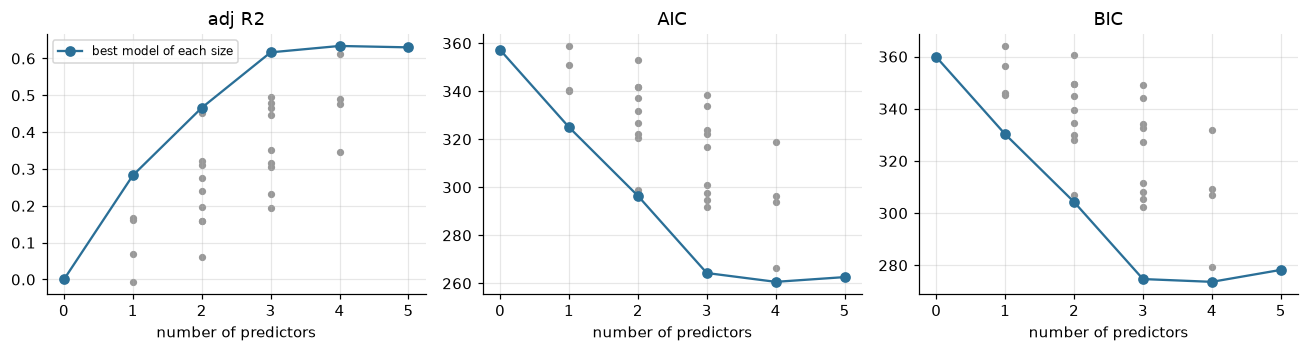

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, crit in zip(axes, ["adj R2", "AIC", "BIC"]):
    ax.scatter(allsub.k, allsub[crit], s=14, color="0.6")
    ax.plot(best_by_k.index, best_by_k[crit], "o-", color="#2a6f97", label="best model of each size")
    ax.set_xlabel("number of predictors"); ax.set_title(crit)
axes[0].legend(fontsize=8)
savefig("p3_criteria_by_size")

**Approach 2 — forward stepwise selection with AIC.**
Start from the intercept-only model. At each step add the predictor that gives the
largest fall in AIC; stop when no addition lowers AIC.

In [17]:
def stepwise_forward(crit="aic"):
    chosen, remaining, path = [], PRED.copy(), []
    current = getattr(fit_formula(chosen), crit)
    path.append({"step": 0, "action": "start (intercept only)", "model": "(intercept only)", crit.upper(): current})
    step = 0
    while remaining:
        scores = {v: getattr(fit_formula(chosen + [v]), crit) for v in remaining}
        v_best = min(scores, key=scores.get)
        if scores[v_best] >= current:
            path.append({"step": step + 1, "action": f"stop: best addition ({v_best}) would give {scores[v_best]:.3f}",
                         "model": " + ".join(chosen), crit.upper(): current})
            break
        step += 1
        chosen.append(v_best); remaining.remove(v_best); current = scores[v_best]
        path.append({"step": step, "action": f"add {v_best}", "model": " + ".join(chosen), crit.upper(): current})
    return chosen, pd.DataFrame(path)

fwd_vars, fwd_path = stepwise_forward("aic")
savetab(fwd_path, "p3_forward_aic", floatfmt=".3f", index=False)
RESULTS["p3_forward_aic"] = fwd_vars
fwd_path

,step,action,model,AIC
0,0,start (intercept only),(intercept only),357.2461
1,1,add x4,x4,325.0287
2,2,add x3,x4 + x3,296.4425
3,3,add x2,x4 + x3 + x2,264.2911
4,4,add x5,x4 + x3 + x2 + x5,260.6167
5,5,stop: best addition (x1) would give 262.593,x4 + x3 + x2 + x5,260.6167


**Approach 3 — backward elimination.**
(i) With BIC: start from the full model and drop the predictor whose removal lowers
BIC the most; stop when no removal lowers BIC.
(ii) With t-tests: drop the least significant predictor while its p-value exceeds 0.05.

In [18]:
def stepwise_backward_crit(crit="bic"):
    chosen = PRED.copy()
    current = getattr(fit_formula(chosen), crit)
    path = [{"step": 0, "action": "start (full model)", "model": " + ".join(chosen), crit.upper(): current}]
    step = 0
    while chosen:
        scores = {v: getattr(fit_formula([c for c in chosen if c != v]), crit) for v in chosen}
        v_drop = min(scores, key=scores.get)
        if scores[v_drop] >= current:
            path.append({"step": step + 1, "action": f"stop: best removal ({v_drop}) would give {scores[v_drop]:.3f}",
                         "model": " + ".join(chosen), crit.upper(): current})
            break
        step += 1
        chosen.remove(v_drop); current = scores[v_drop]
        path.append({"step": step, "action": f"drop {v_drop}", "model": " + ".join(chosen) or "(intercept only)", crit.upper(): current})
    return chosen, pd.DataFrame(path)

bwd_vars, bwd_path = stepwise_backward_crit("bic")
savetab(bwd_path, "p3_backward_bic", floatfmt=".3f", index=False)
RESULTS["p3_backward_bic"] = bwd_vars

def backward_pvalue(alpha_=0.05):
    chosen, path = PRED.copy(), []
    while chosen:
        f = fit_formula(chosen)
        p = f.pvalues.drop("Intercept")
        worst = p.idxmax()
        path.append({"model": " + ".join(chosen), "least significant": worst, "p-value": p[worst],
                     "action": f"drop {worst}" if p[worst] > alpha_ else "stop (all p < 0.05)"})
        if p[worst] <= alpha_:
            break
        chosen.remove(worst)
    return chosen, pd.DataFrame(path)

bwp_vars, bwp_path = backward_pvalue()
savetab(bwp_path, "p3_backward_p", floatfmt=".4f", index=False)
RESULTS["p3_backward_p"] = bwp_vars
display(bwd_path); display(bwp_path)

,step,action,model,BIC
0,0,start (full model),x1 + x2 + x3 + x4 + x5,278.2235
1,1,drop x1,x2 + x3 + x4 + x5,273.6425
2,2,stop: best removal (x5) would give 274.712,x2 + x3 + x4 + x5,273.6425


,model,least significant,p-value,action
0,x1 + x2 + x3 + x4 + x5,x1,0.8805,drop x1
1,x2 + x3 + x4 + x5,x5,0.0206,stop (all p < 0.05)


**Out-of-sample check.** 10-fold cross-validated mean squared error for the
candidate models picked above and for the full model (fixed fold split, seed 3).

In [19]:
def cv_mse(vars_, k=10, seed=3):
    idx = np.random.default_rng(seed).permutation(len(ms))
    folds = np.array_split(idx, k)
    err = []
    for f_ in folds:
        tr = ms.drop(ms.index[f_]); te = ms.iloc[f_]
        rhs = " + ".join(vars_) if vars_ else "1"
        m = smf.ols(f"y ~ {rhs}", data=tr).fit()
        err.append(((te["y"] - m.predict(te)) ** 2).mean())
    return float(np.mean(err))

cands = {"adj R2 best": best["adj R2"], "AIC best": best["AIC"], "BIC best": best["BIC"],
         "forward AIC": " + ".join(fwd_vars), "backward BIC": " + ".join(bwd_vars),
         "backward p-value": " + ".join(bwp_vars), "full model": " + ".join(PRED)}
# also the best model with one predictor fewer than the BIC choice, to judge the marginal variable
_kb = len(best["BIC"].split(" + "))
if _kb > 1:
    cands[f"best {_kb - 1}-predictor model"] = best_by_k.loc[_kb - 1, "model"]
cv = pd.DataFrame([{"selected by": k, "model": v,
                    "k": len(v.split(" + ")) if v and v != "(intercept only)" else 0,
                    "10-fold CV MSE": cv_mse(v.split(" + ") if v and v != "(intercept only)" else [])}
                   for k, v in cands.items()])
savetab(cv, "p3_cv", floatfmt=".4f", index=False)
display(cv)

# Is the CV gap between the BIC model and the best smaller model meaningful?
def cv_fold_errors(vars_, k=10, seed=3):
    idx = np.random.default_rng(seed).permutation(len(ms))
    out = []
    for f_ in np.array_split(idx, k):
        tr = ms.drop(ms.index[f_]); te = ms.iloc[f_]
        m = smf.ols("y ~ " + " + ".join(vars_), data=tr).fit()
        out.append(((te["y"] - m.predict(te)) ** 2).mean())
    return np.array(out)
if _kb > 1:
    small = best_by_k.loc[_kb - 1, "model"].split(" + ")
    diffs = cv_fold_errors(best["BIC"].split(" + ")) - cv_fold_errors(small)
    RESULTS.update({"p3_cv_diff": float(diffs.mean()), "p3_cv_diff_se": float(diffs.std(ddof=1) / np.sqrt(len(diffs))),
                    "p3_cv_small": " + ".join(small)})
    print(f"CV MSE difference (BIC model minus {' + '.join(small)}): {diffs.mean():.4f}, "
          f"s.e. {diffs.std(ddof=1)/np.sqrt(len(diffs)):.4f}")

,selected by,model,k,10-fold CV MSE
0,adj R2 best,x2 + x3 + x4 + x5,4,0.8537
1,AIC best,x2 + x3 + x4 + x5,4,0.8537
2,BIC best,x2 + x3 + x4 + x5,4,0.8537
3,forward AIC,x4 + x3 + x2 + x5,4,0.8537
4,backward BIC,x2 + x3 + x4 + x5,4,0.8537
5,backward p-value,x2 + x3 + x4 + x5,4,0.8537
6,full model,x1 + x2 + x3 + x4 + x5,5,0.8652
7,best 3-predictor model,x2 + x3 + x4,3,0.8463


CV MSE difference (BIC model minus x2 + x3 + x4): 0.0075, s.e. 0.0641


**Final model and diagnostics.** The final model is the one chosen by BIC (see the
report for the reasoning). We check the residuals for non-normality,
heteroskedasticity and non-linearity.

In [20]:
final_vars = best["BIC"].split(" + ") if best["BIC"] != "(intercept only)" else []
final = fit_formula(final_vars)
print(final.summary())
final_tab = pd.DataFrame({"coef": final.params, "std err": final.bse, "t": final.tvalues,
                          "p-value": final.pvalues, "95% low": final.conf_int()[0], "95% high": final.conf_int()[1]})
savetab(final_tab, "p3_final", floatfmt=".4f")
jb = jarque_bera(final.resid)
bp = het_breuschpagan(final.resid, final.model.exog)
reset = sm.stats.diagnostic.linear_reset(final, power=2, use_f=True)
diag = pd.DataFrame({"statistic": [jb[0], bp[0], float(reset.fvalue)],
                     "p-value": [jb[1], bp[1], float(reset.pvalue)]},
                    index=["Jarque-Bera (normality)", "Breusch-Pagan (heteroskedasticity)", "RESET (functional form)"])
savetab(diag, "p3_diag", floatfmt=".4f")
RESULTS.update({"p3_final": final_vars, "p3_final_r2": final.rsquared, "p3_final_adjr2": final.rsquared_adj,
                "p3_final_aic": final.aic, "p3_final_bic": final.bic})
diag

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     43.87
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           8.29e-21
Time:                        17:46:59   Log-Likelihood:                -125.31
No. Observations:                 100   AIC:                             260.6
Df Residuals:                      95   BIC:                             273.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1893      0.089     13.333      0.0

,statistic,p-value
Jarque-Bera (normality),3.9202,0.1408
Breusch-Pagan (heteroskedasticity),2.4820,0.6479
RESET (functional form),0.0046,0.9462


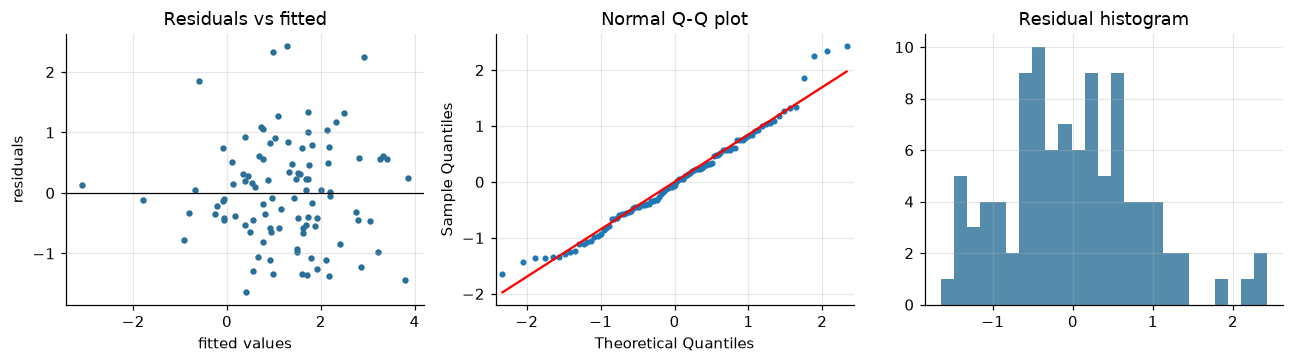

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].scatter(final.fittedvalues, final.resid, s=10, color="#2a6f97")
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_xlabel("fitted values"); axes[0].set_ylabel("residuals")
axes[0].set_title("Residuals vs fitted")
sm.qqplot(final.resid, line="s", ax=axes[1], markersize=3); axes[1].set_title("Normal Q-Q plot")
axes[2].hist(final.resid, bins=25, color="#2a6f97", alpha=0.8); axes[2].set_title("Residual histogram")
savefig("p3_final_diag")

### 3b — AIC versus BIC: simulation that supports the proof in the report

True model $y_i = 1 + 2x_i + \varepsilon_i$. The candidate "big" model also includes
an irrelevant regressor $z_i$ (independent of x and ε). For each n we count how often
each criterion prefers the big (wrong) model. Theory: for AIC this rate tends to
$P(\chi^2_1 > 2) \approx 0.157$; for BIC it tends to 0.

In [22]:
rng = np.random.default_rng(99)
R = 2000
rows = []
for n in [25, 50, 100, 500, 1_000, 5_000, 20_000]:
    pick_aic = pick_bic = 0
    for _ in range(R):
        x_ = rng.normal(size=n); z_ = rng.normal(size=n)
        y_ = 1 + 2 * x_ + rng.normal(size=n)
        X1 = np.column_stack([np.ones(n), x_]); X2 = np.column_stack([X1, z_])
        rss1 = np.sum((y_ - X1 @ np.linalg.lstsq(X1, y_, rcond=None)[0]) ** 2)
        rss2 = np.sum((y_ - X2 @ np.linalg.lstsq(X2, y_, rcond=None)[0]) ** 2)
        lr = n * np.log(rss1 / rss2)
        pick_aic += lr > 2; pick_bic += lr > np.log(n)
    rows.append({"n": n, "P(AIC picks wrong model)": pick_aic / R,
                 "P(BIC picks wrong model)": pick_bic / R,
                 "asymptotic AIC rate": stats.chi2.sf(2, 1),
                 "P(chi2_1 > ln n)": stats.chi2.sf(np.log(n), 1)})
p3b = pd.DataFrame(rows)
savetab(p3b, "p3b_sim", floatfmt=".4f", index=False)
RESULTS["p3b_chi2_sf2"] = float(stats.chi2.sf(2, 1))
p3b

,n,P(AIC picks wrong model),P(BIC picks wrong model),asymptotic AIC rate,P(chi2_1 > ln n)
0,25,0.1960,0.0995,0.1573,0.0728
1,50,0.1760,0.0555,0.1573,0.0479
2,100,0.1450,0.0320,0.1573,0.0319
3,500,0.1555,0.0125,0.1573,0.0127
4,1000,0.1625,0.0070,0.1573,0.0086
5,5000,0.1675,0.0020,0.1573,0.0035
6,20000,0.1670,0.0015,0.1573,0.0016


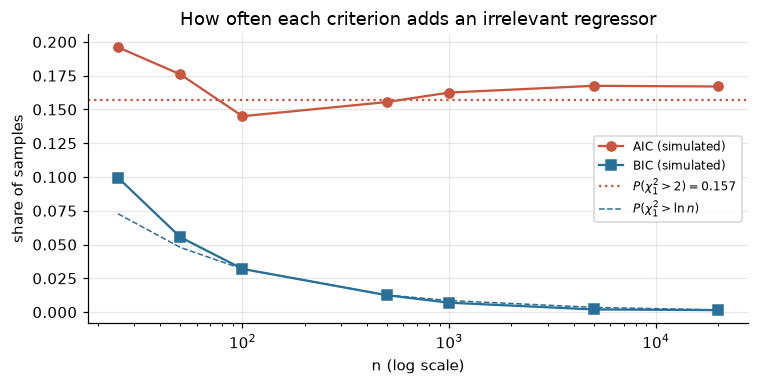

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(p3b.n, p3b["P(AIC picks wrong model)"], "o-", color="#c8553d", label="AIC (simulated)")
ax.plot(p3b.n, p3b["P(BIC picks wrong model)"], "s-", color="#2a6f97", label="BIC (simulated)")
ax.axhline(stats.chi2.sf(2, 1), color="#c8553d", ls=":", label=r"$P(\chi^2_1>2)=0.157$")
ax.plot(p3b.n, p3b["P(chi2_1 > ln n)"], "--", color="#2a6f97", lw=1, label=r"$P(\chi^2_1>\ln n)$")
ax.set_xscale("log"); ax.set_xlabel("n (log scale)"); ax.set_ylabel("share of samples")
ax.set_title("How often each criterion adds an irrelevant regressor")
ax.legend(fontsize=8)
savefig("p3b_sim")

---
## Problem 4 — Interpreting the wage regression
All numbers below come from the coefficient table given in the assignment.

In [24]:
coef = pd.DataFrame({"coef": [0.85, 0.08, -0.15, 0.19, -0.002, 0.22],
                     "se": [0.12, 0.01, 0.10, 0.06, 0.0003, 0.04]},
                    index=["intercept", "educ", "gender", "age", "age^2", "degree"])
n_obs, k_par = 2000, 6
df_res = n_obs - k_par
coef["t"] = coef.coef / coef.se
coef["p (two-sided)"] = 2 * stats.t.sf(coef.t.abs(), df_res)
tcrit = stats.t.ppf(0.975, df_res)
coef["95% low"] = coef.coef - tcrit * coef.se
coef["95% high"] = coef.coef + tcrit * coef.se
coef["exact % effect 100(e^b - 1)"] = 100 * (np.exp(coef.coef) - 1)
coef.loc[["intercept", "age", "age^2"], "exact % effect 100(e^b - 1)"] = np.nan
savetab(coef, "p4_table", floatfmt=".4f")
coef

,coef,se,t,p (two-sided),95% low,95% high,exact % effect 100(e^b - 1)
intercept,0.8500,0.1200,7.0833,0.0000,0.6147,1.0853,NaN
educ,0.0800,0.0100,8.0000,0.0000,0.0604,0.0996,8.3287
gender,-0.1500,0.1000,-1.5000,0.1338,-0.3461,0.0461,-13.9292
age,0.1900,0.0600,3.1667,0.0016,0.0723,0.3077,NaN
age^2,-0.0020,0.0003,-6.6667,0.0000,-0.0026,-0.0014,NaN
degree,0.2200,0.0400,5.5000,0.0000,0.1416,0.2984,24.6077


In [25]:
b = coef.coef
peak = -b["age"] / (2 * b["age^2"])
p_gender_one_sided = stats.t.cdf(coef.loc["gender", "t"], df_res)
kennedy = 100 * (np.exp(b["degree"] - 0.5 * coef.loc["degree", "se"] ** 2) - 1)
ci_deg = 100 * (np.exp(coef.loc["degree", ["95% low", "95% high"]].values) - 1)
ci_gen = 100 * (np.exp(coef.loc["gender", ["95% low", "95% high"]].values) - 1)
RESULTS.update({"p4_peak": float(peak), "p4_gender_p2": float(coef.loc["gender", "p (two-sided)"]),
                "p4_gender_p1": float(p_gender_one_sided), "p4_degree_pct": float(100 * (np.exp(b["degree"]) - 1)),
                "p4_degree_kennedy": float(kennedy), "p4_degree_ci": [float(v) for v in ci_deg],
                "p4_gender_ci": [float(v) for v in ci_gen], "p4_gender_pct": float(100 * (np.exp(b["gender"]) - 1)),
                "p4_educ_pct": float(100 * (np.exp(b["educ"]) - 1)), "p4_tcrit": float(tcrit)})
print(f"Peak age: {peak:.2f} years")
print(f"Gender: two-sided p = {coef.loc['gender', 'p (two-sided)']:.4f}, one-sided p = {p_gender_one_sided:.4f}")
print(f"Degree premium: {100*(np.exp(b['degree'])-1):.2f}% (Kennedy-corrected {kennedy:.2f}%), 95% CI {ci_deg.round(2)}")

Peak age: 47.50 years
Gender: two-sided p = 0.1338, one-sided p = 0.0669
Degree premium: 24.61% (Kennedy-corrected 24.51%), 95% CI [15.21 34.78]


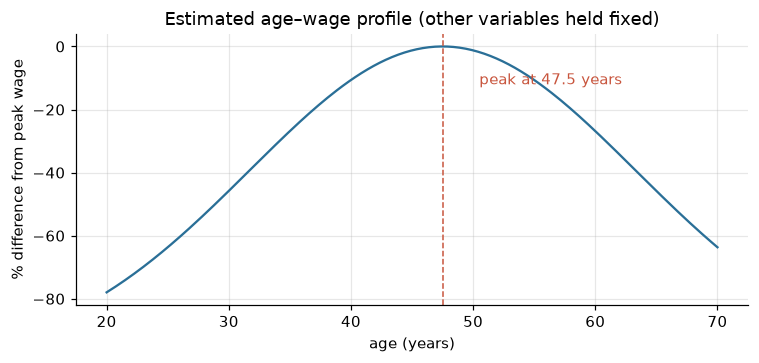

In [26]:
ages = np.linspace(20, 70, 200)
profile = b["age"] * ages + b["age^2"] * ages ** 2
profile -= profile.max()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(ages, 100 * (np.exp(profile) - 1), color="#2a6f97")
ax.axvline(peak, color="#c8553d", ls="--", lw=1)
ax.annotate(f"peak at {peak:.1f} years", (peak, 0), xytext=(peak + 3, -12), color="#c8553d")
ax.set_xlabel("age (years)"); ax.set_ylabel("% difference from peak wage")
ax.set_title("Estimated age–wage profile (other variables held fixed)")
savefig("p4_age_profile")

---
## Problem 5 — Non-stationary series and cointegration

### 5a/5b — Illustration with our own simulation
We simulate the model in the question (T = 500, all shocks N(0,1)) to see that
X, Y and Z wander, while the combinations X − 2Y and X + Z do not.

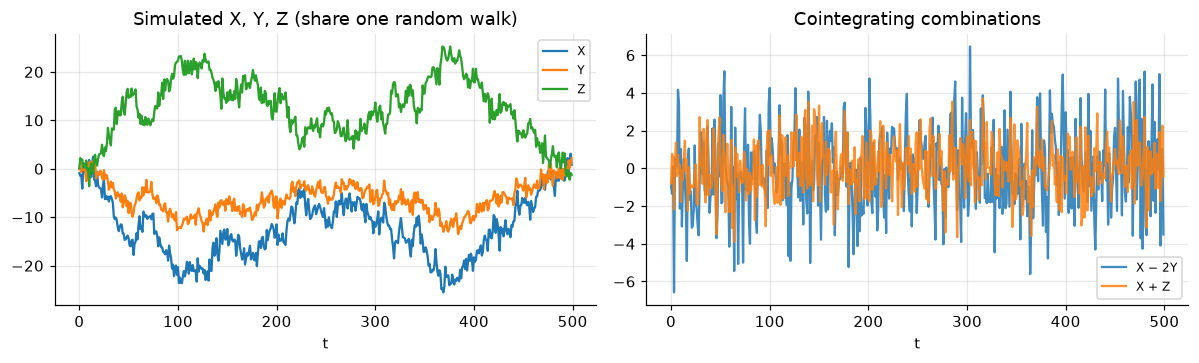

ADF p-values -> X: 0.4491  X-2Y: 0.0  X+Z: 0.0


In [27]:
rng = np.random.default_rng(5)
T = 500
eps = rng.normal(size=T); eps[0] = 0.0      # w(0) = 0
wt = np.cumsum(eps)
Xs = 1.0 * wt + rng.normal(size=T); Ys = 0.5 * wt + rng.normal(size=T); Zs = -1.0 * wt + rng.normal(size=T)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(Xs, label="X"); axes[0].plot(Ys, label="Y"); axes[0].plot(Zs, label="Z")
axes[0].set_title("Simulated X, Y, Z (share one random walk)"); axes[0].legend(fontsize=8)
axes[1].plot(Xs - 2 * Ys, label="X − 2Y", alpha=0.85); axes[1].plot(Xs + Zs, label="X + Z", alpha=0.85)
axes[1].set_title("Cointegrating combinations"); axes[1].legend(fontsize=8)
for ax in axes: ax.set_xlabel("t")
savefig("p5ab_sim")
print("ADF p-values -> X:", round(adfuller(Xs)[1], 4), " X-2Y:", round(adfuller(Xs - 2 * Ys)[1], 4),
      " X+Z:", round(adfuller(Xs + Zs)[1], 4))

### 5c — Data set `FE-GWP1_dataset_Prob5.csv`
**Step 1: load and inspect.**

In [28]:
p5_path = os.path.join(DATA_DIR, "FE-GWP1_dataset_Prob5.csv")
# The file wraps each whole row (header included) in one pair of double quotes and
# starts with a byte-order mark, so a plain read_csv sees a single column.
# Strip the outer quotes from each line before parsing.
from io import StringIO
with open(p5_path, encoding="utf-8-sig") as fh:
    lines = [ln.strip().strip('"') for ln in fh if ln.strip()]
raw5 = pd.read_csv(StringIO("\n".join(lines)))
print(raw5.head()); print(raw5.shape)
cols = {c: c.strip().upper() for c in raw5.columns}
d5 = raw5.rename(columns=cols)
date_col = [c for c in d5.columns if c not in ["X", "Y", "Z"]]
if date_col:
    d5.index = d5[date_col[0]]          # "Period" = 1, 2, ..., T
    d5.index.name = date_col[0]
d5 = d5[["X", "Y", "Z"]].astype(float).dropna()
RESULTS["p5_T"] = int(len(d5))
savetab(d5.describe().T, "p5_describe", floatfmt=".3f")
d5.describe().T

   Period      X       Y       Z
0       1 0.0822  0.5772 -0.3124
1       2 0.0784 -0.3177 -0.5551
2       3 1.3798  0.8373 -0.9918
3       4 2.8344  1.6895 -1.8899
4       5 2.2846  1.1247 -2.1995
(300, 4)


,count,mean,std,min,25%,50%,75%,max
X,300.0000,-5.9849,4.5704,-13.7520,-10.0397,-6.2831,-2.4028,4.3795
Y,300.0000,-2.3485,1.9371,-6.1891,-3.9768,-2.6175,-0.8022,2.5403
Z,300.0000,6.0233,4.5388,-4.3200,2.3062,6.6346,9.9631,13.8761


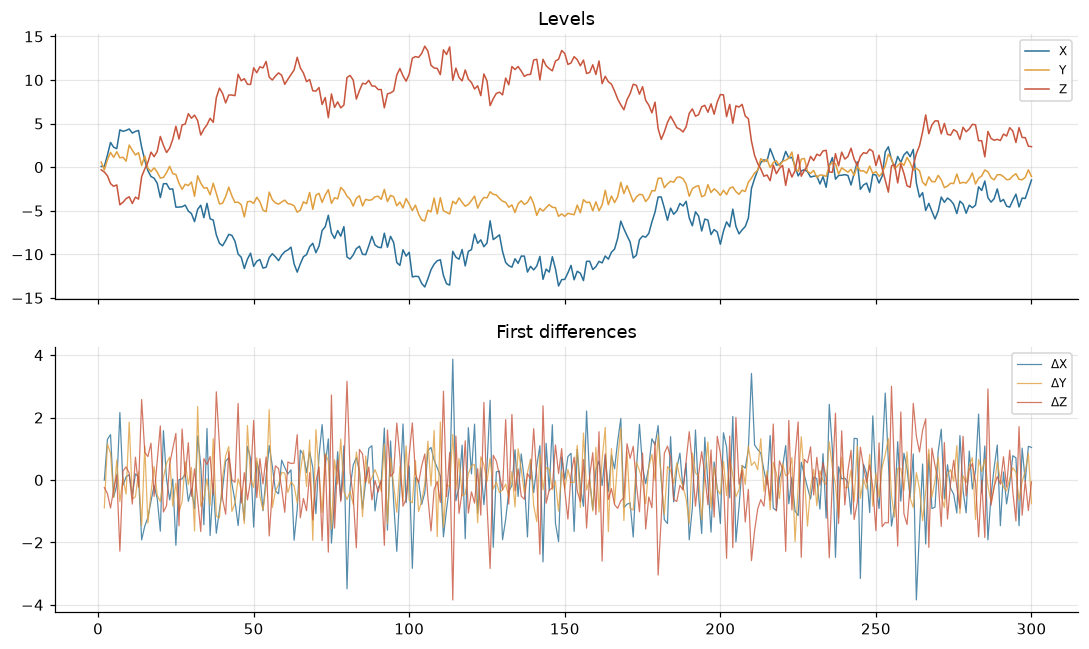

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for c, col in zip(["X", "Y", "Z"], ["#2a6f97", "#e09f3e", "#c8553d"]):
    axes[0].plot(d5.index, d5[c], label=c, color=col, lw=1)
    axes[1].plot(d5.index, d5[c].diff(), label=f"Δ{c}", color=col, lw=0.8, alpha=0.8)
axes[0].set_title("Levels"); axes[1].set_title("First differences")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
savefig("p5c_levels")

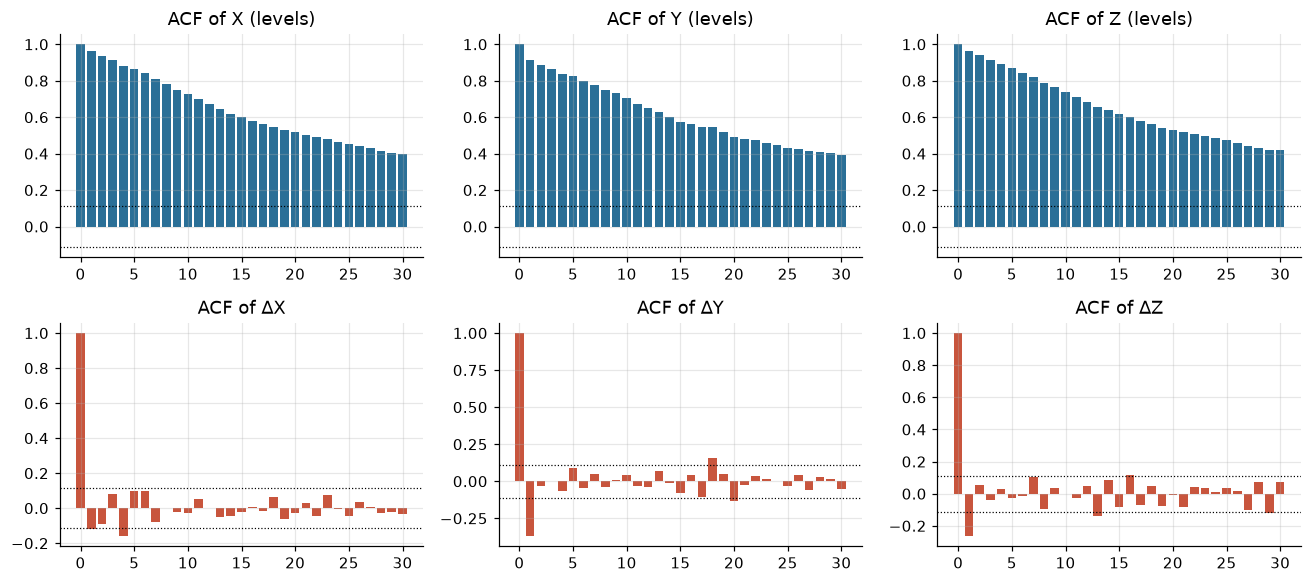

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.4))
for j, c in enumerate(["X", "Y", "Z"]):
    ac = acf(d5[c], nlags=30)
    axes[0, j].bar(range(31), ac, color="#2a6f97"); axes[0, j].set_title(f"ACF of {c} (levels)")
    ac2 = acf(d5[c].diff().dropna(), nlags=30)
    axes[1, j].bar(range(31), ac2, color="#c8553d"); axes[1, j].set_title(f"ACF of Δ{c}")
    for ax in axes[:, j]:
        ax.axhline(1.96 / np.sqrt(len(d5)), color="k", ls=":", lw=0.8)
        ax.axhline(-1.96 / np.sqrt(len(d5)), color="k", ls=":", lw=0.8)
savefig("p5c_acf")

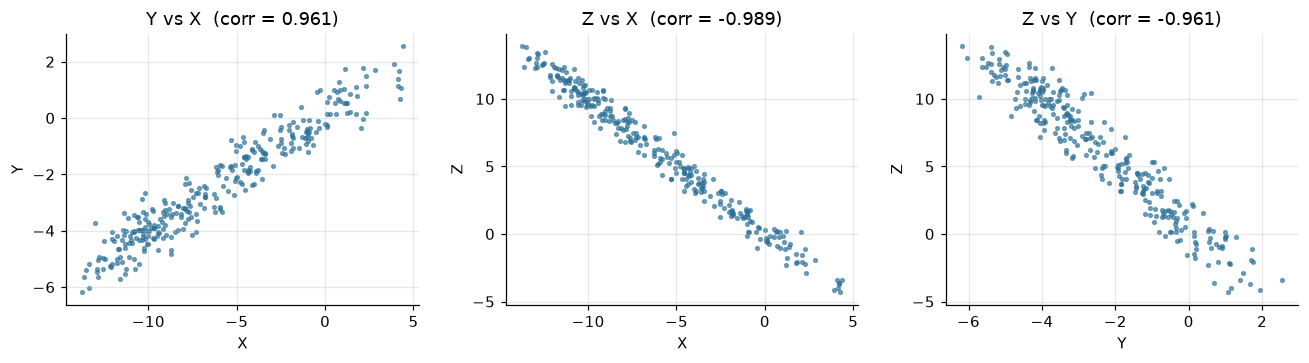

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (a_, b_) in zip(axes, [("X", "Y"), ("X", "Z"), ("Y", "Z")]):
    ax.scatter(d5[a_], d5[b_], s=6, alpha=0.6, color="#2a6f97")
    ax.set_xlabel(a_); ax.set_ylabel(b_); ax.set_title(f"{b_} vs {a_}  (corr = {d5[a_].corr(d5[b_]):.3f})")
savefig("p5c_scatter")

**Step 2: unit-root tests.** ADF (null: unit root) with a constant, lag length chosen
by AIC, on levels and first differences. KPSS (null: level stationarity) is run as a
cross-check, because the two tests have opposite null hypotheses.

In [32]:
rows = []
for c in ["X", "Y", "Z"]:
    for lab, s in [("level", d5[c]), ("first difference", d5[c].diff().dropna())]:
        adf_c = adfuller(s, regression="c", autolag="AIC")
        adf_ct = adfuller(s, regression="ct", autolag="AIC")
        kp = kpss(s, regression="c", nlags="auto")
        rows.append({"series": c, "form": lab,
                     "ADF(c) stat": adf_c[0], "ADF(c) p": adf_c[1], "lags": adf_c[2],
                     "ADF(ct) stat": adf_ct[0], "ADF(ct) p": adf_ct[1],
                     "KPSS stat": kp[0], "KPSS p": kp[1]})
ur = pd.DataFrame(rows)
savetab(ur, "p5c_unitroot", floatfmt=".4f", index=False)
ur

,series,form,ADF(c) stat,ADF(c) p,lags,ADF(ct) stat,ADF(ct) p,KPSS stat,KPSS p
0,X,level,-2.4862,0.1189,6,-2.6430,0.2605,0.7669,0.0100
1,X,first difference,-10.3397,0.0000,3,-10.4635,0.0000,0.1621,0.1000
2,Y,level,-2.0803,0.2525,4,-2.7656,0.2099,0.8158,0.0100
3,Y,first difference,-12.0124,0.0000,3,-12.1122,0.0000,0.1960,0.1000
4,Z,level,-1.9667,0.3014,1,-2.4535,0.3516,0.7946,0.0100
5,Z,first difference,-22.5105,0.0000,0,-22.5487,0.0000,0.1934,0.1000


**Step 3: lag order.** Choose the VAR lag length in levels with information criteria;
the VECM then uses $k_{ar\_diff} = p - 1$ lagged differences.

In [33]:
sel = VAR(d5).select_order(maxlags=10, trend="c")
print(sel.summary())
ic_tab = pd.DataFrame({ic: [sel.ics[ic][i] for i in range(len(sel.ics[ic]))] for ic in ["aic", "bic", "hqic"]})
ic_tab.index.name = "p"
savetab(ic_tab, "p5c_lagselect", floatfmt=".4f")
p_bic = int(sel.selected_orders["bic"]); p_aic = int(sel.selected_orders["aic"])
p_var = max(p_bic, 1)
k_diff = p_var - 1                      # VAR(p) in levels -> VECM with p-1 lagged differences
RESULTS.update({"p5_p_aic": p_aic, "p5_p_bic": p_bic, "p5_kdiff": k_diff})
print("VAR lag chosen by BIC:", p_bic, " by AIC:", p_aic, " -> k_ar_diff used:", k_diff)

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       0.8447      0.8826       2.327      0.8599
1      -1.946*     -1.794*     0.1429*     -1.885*
2       -1.929      -1.664      0.1452      -1.823
3       -1.887      -1.507      0.1515      -1.735
4       -1.853      -1.359      0.1569      -1.655
5       -1.831      -1.223      0.1604      -1.587
6       -1.812      -1.091      0.1633      -1.523
7       -1.821     -0.9854      0.1621      -1.486
8       -1.765     -0.8157      0.1714      -1.385
9       -1.708     -0.6451      0.1815      -1.282
10      -1.659     -0.4818      0.1908      -1.187
--------------------------------------------------
VAR lag chosen by BIC: 1  by AIC: 1  -> k_ar_diff used: 0


**Step 4: Johansen test.**

*Choice of deterministic terms.* The levels wander but show no steady upward or
downward drift, and the model in the question has no deterministic terms. The
standard choice for such data is a constant **restricted to the cointegrating
relations** (Johansen's "case 2"): it lets each long-run relation have a non-zero mean
without implying a trend in the levels. It also matches the VECM we estimate in Step 5
(`deterministic="ci"`).

statsmodels' `coint_johansen` offers only no deterministic terms (`det_order=-1`), an
unrestricted constant (`det_order=0`) or a trend, so we compute the restricted-constant
test directly with the reduced-rank regression below. To check the code, we first
run it on the two cases statsmodels supports and confirm the numbers match.

In [34]:
def johansen_rr(y, k_diff, case):
    """Johansen reduced-rank regression.
    case: 'none' = no deterministic terms, 'rc' = constant restricted to the
    cointegration space, 'uc' = unrestricted constant.
    Returns eigenvalues, trace statistics and max-eigenvalue statistics for r = 0..n-1."""
    y = np.asarray(y, float); n = y.shape[1]
    dy = np.diff(y, axis=0)
    T = dy.shape[0] - k_diff
    Z0 = dy[k_diff:]                                   # Δy_t
    Z1 = y[k_diff:-1]                                  # y_{t-1}
    Z2 = (np.column_stack([dy[k_diff - j:-j] for j in range(1, k_diff + 1)])
          if k_diff else np.empty((T, 0)))             # lagged differences
    if case == "rc": Z1 = np.column_stack([Z1, np.ones(T)])
    if case == "uc": Z2 = np.column_stack([Z2, np.ones(T)])
    if Z2.shape[1]:
        B = np.linalg.lstsq(Z2, np.column_stack([Z0, Z1]), rcond=None)[0]
        R = np.column_stack([Z0, Z1]) - Z2 @ B
        R0, R1 = R[:, :n], R[:, n:]
    else:
        R0, R1 = Z0, Z1
    S00, S11, S01 = R0.T @ R0 / T, R1.T @ R1 / T, R0.T @ R1 / T
    from scipy import linalg
    lam = linalg.eigh(S01.T @ np.linalg.solve(S00, S01), S11, eigvals_only=True)[::-1][:n]
    lam = np.clip(lam, 0, 1 - 1e-12)
    trace = np.array([-T * np.sum(np.log(1 - lam[r:])) for r in range(n)])
    maxeig = -T * np.log(1 - lam)
    return lam, trace, maxeig

# Validation against statsmodels for the cases it supports
chk = []
for case, det in [("none", -1), ("uc", 0)]:
    lam, tr, me = johansen_rr(d5, k_diff, case)
    jo_ = coint_johansen(d5, det, k_diff)
    chk.append({"case": case, "max |diff| eigenvalues": np.abs(lam - jo_.eig).max(),
                "max |diff| trace": np.abs(tr - jo_.lr1).max(), "max |diff| max-eig": np.abs(me - jo_.lr2).max()})
pd.DataFrame(chk)

,case,max |diff| eigenvalues,max |diff| trace,max |diff| max-eig
0,none,0.0018,1.1164,1.0512
1,uc,0.0037,1.1357,1.4150


*Critical values for the restricted-constant case.* The asymptotic distributions depend
only on n − r and on the deterministic case. We simulate them: for m = n − r = 1, 2, 3,
generate m independent random walks of length 500, compute the r = 0 statistics, and
repeat 20,000 times (seed 2025). The resulting 90/95/99% quantiles agree closely with the
published Osterwald-Lenum (1992) tables for this case. The same draws give a p-value for
each observed statistic.

In [35]:
rng = np.random.default_rng(2025)
sim_tr, sim_me = {}, {}
for m in [1, 2, 3]:
    draws = np.array([johansen_rr(np.cumsum(rng.standard_normal((500, m)), axis=0), 0, "rc")[1:]
                      for _ in range(20_000)])
    sim_tr[m], sim_me[m] = draws[:, 0, 0], draws[:, 1, 0]
cv_tab = pd.DataFrame({"n - r": [1, 2, 3],
                       **{f"trace {q:.0%}": [np.quantile(sim_tr[m], q) for m in [1, 2, 3]] for q in [0.90, 0.95, 0.99]},
                       **{f"max-eig {q:.0%}": [np.quantile(sim_me[m], q) for m in [1, 2, 3]] for q in [0.90, 0.95, 0.99]}})
savetab(cv_tab, "p5c_cv_sim", floatfmt=".2f", index=False)
cv_tab

,n - r,trace 90%,trace 95%,trace 99%,max-eig 90%,max-eig 95%,max-eig 99%
0,1,7.5684,9.1101,12.6693,7.5684,9.1101,12.6693
1,2,18.0007,20.2746,24.9776,13.9283,15.8611,19.9926
2,3,32.4449,35.4050,41.5426,20.2178,22.5203,27.5493


*Test results.* We read each test sequentially (r = 0, then r ≤ 1, ...) and stop at the
first null hypothesis not rejected at 5%.

In [36]:
def johansen_rc_table(k):
    lam, tr, me = johansen_rr(d5, k, "rc")
    rows = []
    for i in range(3):
        m = 3 - i
        rows.append({"H0": "r = 0" if i == 0 else f"r ≤ {i}", "eigenvalue": lam[i],
                     "trace stat": tr[i], "trace 95%": np.quantile(sim_tr[m], 0.95),
                     "trace p": (sim_tr[m] >= tr[i]).mean(),
                     "max-eig stat": me[i], "max-eig 95%": np.quantile(sim_me[m], 0.95),
                     "max-eig p": (sim_me[m] >= me[i]).mean()})
    tab = pd.DataFrame(rows)
    r_tr = next((i for i in range(3) if tab["trace p"][i] > 0.05), 3)
    r_me = next((i for i in range(3) if tab["max-eig p"][i] > 0.05), 3)
    return tab, r_tr, r_me

jtab, r_trace, r_maxeig = johansen_rc_table(k_diff)
savetab(jtab, "p5c_johansen", floatfmt=".3f", index=False)
RESULTS.update({"p5_r_trace": r_trace, "p5_r_maxeig": r_maxeig,
                "p5_trace_r2": float(jtab["trace stat"][2]), "p5_trace_r2_p": float(jtab["trace p"][2])})
print("Rank at 5% (restricted constant) — trace:", r_trace, " max-eig:", r_maxeig)
jtab

Rank at 5% (restricted constant) — trace: 2  max-eig: 2


,H0,eigenvalue,trace stat,trace 95%,trace p,max-eig stat,max-eig 95%,max-eig p
0,r = 0,0.5405,435.8133,35.4050,0.0000,232.5352,22.5203,0.0000
1,r ≤ 1,0.4854,203.2781,20.2746,0.0000,198.6170,15.8611,0.0000
2,r ≤ 2,0.0155,4.6610,9.1101,0.3201,4.6610,9.1101,0.3201


*Robustness.* The same test with more lagged differences, and statsmodels' two
alternative deterministic specifications (with its built-in critical values).

In [37]:
rows = []
for k in sorted(set([0, 1, 2, 3, 4, k_diff])):
    _, rt, rm = johansen_rc_table(k)
    rows.append({"deterministic terms": "restricted constant", "k_ar_diff": k,
                 "rank (trace, 5%)": rt, "rank (max-eig, 5%)": rm})
sm_rows = []
for det, lab in [(-1, "none (statsmodels det_order=-1)"), (0, "unrestricted constant (statsmodels det_order=0)")]:
    for kk in sorted(set([k_diff, k_diff + 1])):
        jo_ = coint_johansen(d5, det, kk)
        rt = next((i for i in range(3) if jo_.lr1[i] < jo_.cvt[i, 1]), 3)
        rm = next((i for i in range(3) if jo_.lr2[i] < jo_.cvm[i, 1]), 3)
        rows.append({"deterministic terms": lab, "k_ar_diff": kk, "rank (trace, 5%)": rt, "rank (max-eig, 5%)": rm})
        if kk == k_diff:
            for i in range(3):
                sm_rows.append({"deterministic terms": lab.split(" (")[0], "H0": "r = 0" if i == 0 else f"r ≤ {i}",
                                "trace stat": jo_.lr1[i], "trace 95%": jo_.cvt[i, 1], "trace 99%": jo_.cvt[i, 2],
                                "max-eig stat": jo_.lr2[i], "max-eig 95%": jo_.cvm[i, 1], "max-eig 99%": jo_.cvm[i, 2]})
        if det == 0 and kk == k_diff + 1:
            RESULTS.update({"p5_uc_k1_r2_stat": float(jo_.lr1[2]), "p5_uc_k1_r2_cv95": float(jo_.cvt[2, 1]),
                            "p5_uc_k1_r2_cv99": float(jo_.cvt[2, 2])})
jrob = pd.DataFrame(rows)
jsm = pd.DataFrame(sm_rows)
savetab(jrob, "p5c_johansen_robust", index=False)
savetab(jsm, "p5c_johansen_sm", floatfmt=".3f", index=False)
jo_uc = coint_johansen(d5, 0, k_diff)
RESULTS.update({"p5_uc_r2_stat": float(jo_uc.lr1[2]), "p5_uc_r2_cv95": float(jo_uc.cvt[2, 1]),
                "p5_uc_r2_cv99": float(jo_uc.cvt[2, 2])})
display(jrob); display(jsm)

,deterministic terms,k_ar_diff,"rank (trace, 5%)","rank (max-eig, 5%)"
0,restricted constant,0,2,2
1,restricted constant,1,2,2
2,restricted constant,2,2,2
3,restricted constant,3,2,2
4,restricted constant,4,2,2
5,none (statsmodels det_order=-1),0,2,2
6,none (statsmodels det_order=-1),1,2,2
7,unrestricted constant (statsmodels det_order=0),0,2,2
8,unrestricted constant (statsmodels det_order=0),1,3,3


,deterministic terms,H0,trace stat,trace 95%,trace 99%,max-eig stat,max-eig 95%,max-eig 99%
0,none,r = 0,423.2206,24.2761,29.5147,222.3448,17.7961,22.2519
1,none,r ≤ 1,200.8758,12.3212,16.3640,199.3679,11.2246,15.0923
2,none,r ≤ 2,1.5079,4.1296,6.9406,1.5079,4.1296,6.9406
3,unrestricted constant,r = 0,435.9961,29.7961,35.4628,232.4623,21.1314,25.8650
4,unrestricted constant,r ≤ 1,203.5338,15.4943,19.9349,200.0235,14.2639,18.5200
5,unrestricted constant,r ≤ 2,3.5103,3.8415,6.6349,3.5103,3.8415,6.6349


**Step 5: VECM.** Estimated with the rank found above, the same lag length, and the
constant restricted to the cointegration relations (`deterministic="ci"`), since the
series show no drift. statsmodels normalises β so that its top $r \times r$ block is the
identity.

In [38]:
r_use = r_trace
RESULTS["p5_r_use"] = int(r_use)
vecm = VECM(d5, k_ar_diff=k_diff, coint_rank=r_use, deterministic="ci").fit()
print(vecm.summary())

                 Loading coefficients (alpha) for equation X                  
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ec1           -0.4709      0.098     -4.828      0.000      -0.662      -0.280
ec2            0.2610      0.124      2.101      0.036       0.017       0.505
                 Loading coefficients (alpha) for equation Y                  
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ec1            0.1487      0.055      2.687      0.007       0.040       0.257
ec2           -0.9335      0.071    -13.240      0.000      -1.072      -0.795
                 Loading coefficients (alpha) for equation Z                  
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------

In [39]:
names = ["X", "Y", "Z"]
beta_tab = pd.DataFrame(vecm.beta, index=names, columns=[f"coint. vector {i+1}" for i in range(r_use)])
beta_se = pd.DataFrame(vecm.stderr_beta, index=names, columns=beta_tab.columns)
if vecm.det_coef_coint.size:
    beta_tab.loc["const"] = vecm.det_coef_coint.ravel()[:r_use]
    beta_se.loc["const"] = vecm.stderr_det_coef_coint.ravel()[:r_use]
beta_out = pd.concat({"estimate": beta_tab, "std err": beta_se}, axis=1)
beta_out.columns = [f"{b}: {a}" for a, b in beta_out.columns]
beta_out = beta_out[[c for v in beta_tab.columns for c in beta_out.columns if c.startswith(v)]]
beta_out = beta_out.astype(float).where(beta_out.abs() > 1e-10, 0.0)
alpha_tab = pd.DataFrame(vecm.alpha, index=[f"Δ{c}" for c in names], columns=[f"ECT {i+1}" for i in range(r_use)])
alpha_se = pd.DataFrame(vecm.stderr_alpha, index=alpha_tab.index, columns=alpha_tab.columns)
alpha_t = alpha_tab / alpha_se
alpha_out = pd.concat({"alpha": alpha_tab, "std err": alpha_se, "t": alpha_t}, axis=1)
alpha_out.columns = [f"{a} ({b})" for a, b in alpha_out.columns]
gamma_tab = None
if k_diff > 0:
    gamma_rows = {}
    for lag in range(k_diff):
        G = vecm.gamma[:, lag * 3:(lag + 1) * 3]
        for i, eq in enumerate(names):
            gamma_rows[(f"Δ{eq}", f"lag {lag+1}")] = G[i]
    gamma_tab = pd.DataFrame(gamma_rows, index=[f"coef. on Δ{c}" for c in names]).T
    gamma_tab.index = [f"{eq} eq., {l}" for eq, l in gamma_tab.index]
    savetab(gamma_tab, "p5c_gamma", floatfmt=".4f")
savetab(beta_out, "p5c_beta", floatfmt=".4f")
savetab(alpha_out, "p5c_alpha", floatfmt=".4f")
if r_use == 2:
    t_theory = [(vecm.beta[2, 0] - 1.0) / vecm.stderr_beta[2, 0], (vecm.beta[2, 1] - 0.5) / vecm.stderr_beta[2, 1]]
    RESULTS.update({"p5_bz1": float(vecm.beta[2, 0]), "p5_bz1_se": float(vecm.stderr_beta[2, 0]),
                    "p5_bz2": float(vecm.beta[2, 1]), "p5_bz2_se": float(vecm.stderr_beta[2, 1]),
                    "p5_bz1_t": float(t_theory[0]), "p5_bz2_t": float(t_theory[1])})
    print("t-stats against theory (Z coef = 1 and 0.5):", np.round(t_theory, 3))
display(beta_out); display(alpha_out)
if gamma_tab is not None: display(gamma_tab)

t-stats against theory (Z coef = 1 and 0.5): [ 0.979 -1.294]


,coint. vector 1: estimate,coint. vector 1: std err,coint. vector 2: estimate,coint. vector 2: std err
X,1.0000,0.0000,0.0000,0.0000
Y,0.0000,0.0000,1.0000,0.0000
Z,1.0084,0.0086,0.4157,0.0651
const,-0.0904,0.0064,-0.1542,0.0482


,alpha (ECT 1),alpha (ECT 2),std err (ECT 1),std err (ECT 2),t (ECT 1),t (ECT 2)
ΔX,-0.4709,0.2610,0.0975,0.1243,-4.8277,2.1007
ΔY,0.1487,-0.9335,0.0554,0.0705,2.6873,-13.2397
ΔZ,-0.5326,-0.2571,0.0981,0.1250,-5.4293,-2.0573


In [40]:
# Robustness of the cointegrating vectors to the number of lagged differences
rows = []
for k in [0, 1, 2]:
    v_ = VECM(d5, k_ar_diff=k, coint_rank=r_use, deterministic="ci").fit()
    wt_ = v_.test_whiteness(nlags=10)
    rows.append({"k_ar_diff": k, "Z coef., vector 1": v_.beta[2, 0], "s.e. (1)": v_.stderr_beta[2, 0],
                 "Z coef., vector 2": v_.beta[2, 1], "s.e. (2)": v_.stderr_beta[2, 1],
                 "log-likelihood": v_.llf, "portmanteau p (10 lags)": wt_.pvalue})
beta_rob = pd.DataFrame(rows)
llf0 = beta_rob["log-likelihood"].iloc[0]
beta_rob["LR vs k=0"] = 2 * (beta_rob["log-likelihood"] - llf0)
beta_rob["LR p"] = [np.nan] + [stats.chi2.sf(lr, 9 * k) for lr, k in zip(beta_rob["LR vs k=0"][1:], beta_rob["k_ar_diff"][1:])]
RESULTS.update({"p5_lr_k1": float(beta_rob["LR vs k=0"].iloc[1]), "p5_lr_k1_p": float(beta_rob["LR p"].iloc[1])})
savetab(beta_rob, "p5c_beta_robust", floatfmt=".4f", index=False)
beta_rob

,k_ar_diff,"Z coef., vector 1",s.e. (1),"Z coef., vector 2",s.e. (2),log-likelihood,portmanteau p (10 lags),LR vs k=0,LR p
0,0,1.0084,0.0086,0.4157,0.0651,-973.6337,0.6917,0.0000,NaN
1,1,1.0059,0.0084,0.4150,0.0630,-963.5238,0.8531,20.2198,0.0166
2,2,1.0057,0.0087,0.4151,0.0658,-957.8891,0.7323,31.4892,0.0253


   coint. vector 1  coint. vector 2
X                1           0.0000
Y                0           1.0000
Z                1           0.5000


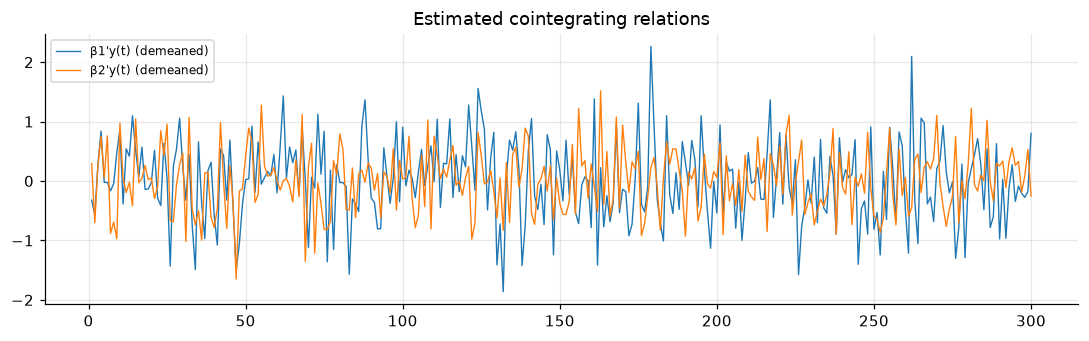

In [41]:
# Theoretical cointegrating vectors in the same normalisation, for comparison
if r_use == 2:
    theory = pd.DataFrame([[1, 0], [0, 1], [1, 0.5]], index=names, columns=beta_tab.columns[:2])
elif r_use == 1:
    theory = None
print(theory)
# Estimated error-correction terms
ect = d5.values @ vecm.beta
fig, ax = plt.subplots(figsize=(10, 3.2))
for i in range(r_use):
    ax.plot(d5.index, ect[:, i] - ect[:, i].mean(), lw=0.9, label=f"β{i+1}'y(t) (demeaned)")
ax.set_title("Estimated cointegrating relations"); ax.legend(fontsize=8)
savefig("p5c_ect")

In [42]:
res = pd.DataFrame(vecm.resid, columns=names)
lb = pd.DataFrame({c: acorr_ljungbox(res[c], lags=[10], return_df=True).iloc[0] for c in names}).T
lb.columns = ["Ljung-Box Q(10)", "p-value"]
wt = vecm.test_whiteness(nlags=10)
lb.loc["Portmanteau (system, 10 lags)"] = [wt.test_statistic, wt.pvalue]
savetab(lb, "p5c_resid", floatfmt=".4f")
lb

,Ljung-Box Q(10),p-value
X,10.8857,0.3665
Y,3.6156,0.9630
Z,9.4318,0.4917
"Portmanteau (system, 10 lags)",77.0394,0.6917


---
## Problem 6 — ARMA representations
### 6a — ψ-weights of AR(1) with φ = 0.5
Numerical check of the hand derivation: ψ_j = 0.5^j.

In [43]:
psi = arma2ma(np.array([1, -0.5]), np.array([1]), lags=6)
p6a = pd.DataFrame({"j": range(6), "psi_j (statsmodels)": psi, "0.5^j": 0.5 ** np.arange(6)})
savetab(p6a, "p6a_psi", floatfmt=".5f", index=False)
p6a

,j,psi_j (statsmodels),0.5^j
0,0,1.0000,1.0000
1,1,0.5000,0.5000
2,2,0.2500,0.2500
3,3,0.1250,0.1250
4,4,0.0625,0.0625
5,5,0.0312,0.0312


### 6b — ACF of AR(2) with φ1 = 0.6, φ2 = 0.2
Theoretical ACF from statsmodels and the sample ACF of a long simulated path
(T = 200,000, seed 6) against the Yule–Walker results ρ1 = 0.75, ρ2 = 0.65.

In [44]:
ar2 = ArmaProcess(ar=[1, -0.6, -0.2], ma=[1])
print("Stationary:", ar2.isstationary, " roots:", np.round(ar2.arroots, 4))
theo = arma_acf([1, -0.6, -0.2], [1], lags=6)
sim = ar2.generate_sample(nsample=200_000, distrvs=np.random.default_rng(6).standard_normal, burnin=1000)
samp = acf(sim, nlags=5)
p6b = pd.DataFrame({"lag": range(6), "Yule-Walker recursion": [1, 0.75, 0.65, 0.6 * 0.65 + 0.2 * 0.75,
                                                               0.6 * (0.6 * 0.65 + 0.2 * 0.75) + 0.2 * 0.65, np.nan],
                    "statsmodels arma_acf": theo, "sample ACF (simulated)": samp})
p6b.loc[5, "Yule-Walker recursion"] = 0.6 * p6b.loc[4, "Yule-Walker recursion"] + 0.2 * p6b.loc[3, "Yule-Walker recursion"]
savetab(p6b, "p6b_acf", floatfmt=".4f", index=False)
RESULTS["p6_roots"] = [float(r) for r in np.real(ar2.arroots)]
p6b

Stationary: True  roots: [-4.1926  1.1926]


,lag,Yule-Walker recursion,statsmodels arma_acf,sample ACF (simulated)
0,0,1.0000,1.0000,1.0000
1,1,0.7500,0.7500,0.7497
2,2,0.6500,0.6500,0.6485
3,3,0.5400,0.5400,0.5393
4,4,0.4540,0.4540,0.4518
5,5,0.3804,0.3804,0.3774


In [45]:
def _clean(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, dict): return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    return o
with open(os.path.join(OUT, "results.json"), "w") as f:
    json.dump(_clean(RESULTS), f, indent=2)
print(json.dumps(_clean(RESULTS), indent=2))

{
  "p1e_corrXZ": 0.4535227935292172,
  "p2b_sens_range_x5": [
    1.452743686459706,
    1.5566845602226103
  ],
  "p2b_sens_range_x25": [
    -0.38263967692433154,
    2.44960455518644
  ],
  "p3_n": 100,
  "p3_full_r2": 0.6488479760272245,
  "p3_full_adjr2": 0.6301696768797365,
  "p3_best_allsub": {
    "adj R2": "x2 + x3 + x4 + x5",
    "AIC": "x2 + x3 + x4 + x5",
    "BIC": "x2 + x3 + x4 + x5"
  },
  "p3_forward_aic": [
    "x4",
    "x3",
    "x2",
    "x5"
  ],
  "p3_backward_bic": [
    "x2",
    "x3",
    "x4",
    "x5"
  ],
  "p3_backward_p": [
    "x2",
    "x3",
    "x4",
    "x5"
  ],
  "p3_cv_diff": 0.007461515365097338,
  "p3_cv_diff_se": 0.06407963336960217,
  "p3_cv_small": "x2 + x3 + x4",
  "p3_final": [
    "x2",
    "x3",
    "x4",
    "x5"
  ],
  "p3_final_r2": 0.6487631415023244,
  "p3_final_adjr2": 0.6339742211445276,
  "p3_final_aic": 260.61668419946966,
  "p3_final_bic": 273.64253512941013,
  "p3b_chi2_sf2": 0.15729920705028105,
  "p4_peak": 47.5,
  "p4_gender_